# Step 4 — the SEI growth PINN (physics enters)

This is the first model in the project that is told *why* capacity falls.
Steps 1 and 2 were pure curve-fitters: a plain MLP and an LSTM, both
trained on mean-squared-error alone, both free to draw whatever shape best
hugged the training points and with no reason to do anything sensible once
the data stopped. This notebook changes the loss (a physics term is added)
and uses a deeper network than step 1: **4 hidden layers, three `tanh`
followed by one `sigmoid`**, rather than step 1's 3-layer all-tanh net.

**What is new:** the network no longer predicts capacity directly. It
predicts a latent *film state* `u`, and capacity is derived from it through
a physical relationship. A second loss term penalises the network whenever
that film state disagrees with the SEI (solid-electrolyte-interphase)
growth law.

**On the activation choice:** the physics loss backpropagates through
`du/dτ`, which pulls in the *second* derivatives of the activations. Both
`tanh` and `sigmoid` are smooth everywhere, so every layer contributes to
that gradient — unlike `ReLU`, whose second derivative is zero almost
everywhere (step 1 §8). The only relaxed control here is that the network
shape now differs from step 1 (deeper, and the last hidden layer is
sigmoid), so the clean "only the loss changed" comparison no longer holds
exactly.

As before, the detailed reasoning lives in comments *inside* each code
cell — the markdown here just says what each section is for.

## 0. Setup

Same imports as the earlier steps, plus `torch.nn.functional` (for
`softplus`, used to keep the film thickness growing) and `math` (for the
log-parametrised physical constants). Seed fixed to 0, matching step 1.

In [1]:
import sys
import math
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("repo:", REPO)

repo: C:\Users\wiece\OneDrive\Desktop\FaradayX\GrunussWorkspace\PaaS4Bat_PINN_CaseStudy_YourName


## 1. Load the data and split

Byte-for-byte the same split as steps 1–3: train on cycles 2–90, hold out
91–132, so "prediction" means genuine extrapolation. Alongside the
labelled training points, the PINN also needs **collocation points** — a
dense grid of cycle values with *no* capacity attached, used only to check
the physics equation. They are what let the ODE be enforced continuously,
not just at the 89 measured cycles.

In [2]:
# Same file, same split as step1/step2: train on cycles 2-90, hold out
# 91-132 so "prediction" means genuine extrapolation, not interpolation.
DATA = REPO / "data" / "processed" / "clean_data.csv"
df = pd.read_csv(DATA, sep=";").sort_values("cycle").reset_index(drop=True)

train_df = df[df.cycle <= 90].reset_index(drop=True)
test_df = df[df.cycle > 90].reset_index(drop=True)
n_max = train_df.cycle.max()

# Cycle number normalised to [0, 1] on the TRAINING range only (test goes
# slightly past 1.0 -- that overshoot is the extrapolation being tested).
tau_train = torch.tensor(train_df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)
q_train = torch.tensor(train_df.capacity_ah.values, dtype=torch.float32).reshape(-1, 1)
tau_test = torch.tensor(test_df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)
q_test_np = test_df.capacity_ah.values

# Dense, unlabelled points where the ODE is enforced. These are NOT data --
# no capacity value is attached to them, only the physics residual is.
tau_col = torch.linspace(0, 1, 256).reshape(-1, 1)

Q0_AH = 1.855  # cycle-1 capacity (capacity_ah / soh is 1.855 for every row -- this is the reference, not the 2.0 Ah rated value)

print(f"train: {len(train_df)} cycles (2-90)   test: {len(test_df)} cycles (91-132)")

train: 89 cycles (2-90)   test: 42 cycles (91-132)


## 2. The model — predict the film, derive the capacity

The one structural idea that separates this from step 1. The network's
output is **not** capacity; it is the SEI film state `u = delta^2`.
Capacity is then computed from `u` through a fixed physical formula. Two
learnable physical constants — the growth rate `k` and the lithium-loss
coefficient `c_Li` — are stored as logarithms so they can never go
negative. The initial condition (full capacity at cycle 1) is built into
the functional form, so it holds *exactly*, not as something the network
has to learn. The comments in the cell explain each of those choices.

In [3]:
class SEIPinn(nn.Module):
    """Predicts the SEI film state, not capacity. Capacity is DERIVED from it.

    Why not just predict capacity directly (like step1's plain MLP)? Because
    then the physics term would only be a soft penalty on an otherwise free
    output -- the network could still express curves that don't correspond
    to a real film thickness. Deriving capacity from u means every
    prediction this model can make already comes from *some* film
    trajectory, physical or not; the loss only has to push that trajectory
    toward the right growth rate, not invent physical structure from
    scratch.
    """

    def __init__(self, hidden=32, delta0=1.0):
        super().__init__()
        # delta0: gauge-fixed initial film thickness. Its absolute value is
        # arbitrary (only differences ever multiply c_li below); fixing it
        # to 1.0 just removes one redundant free parameter.
        self.delta0 = delta0

        # 4 hidden layers: three tanh then one sigmoid. Deeper than step1's
        # 3-layer all-tanh net, so the "only the loss changed vs. step1"
        # control is relaxed -- the network shape differs too.
        #
        # Both tanh and sigmoid are SMOOTH everywhere, which matters here:
        # the physics loss backprops THROUGH du/dtau (physics_residual uses
        # create_graph=True), pulling in the activations' second derivatives.
        # Unlike ReLU (whose second derivative is zero a.e. and undefined at
        # its kinks -- step1, section 8), every layer here contributes real
        # curvature to the physics gradient, so nothing is silently dropped.
        activations = [nn.Tanh, nn.Tanh, nn.Tanh, nn.Sigmoid]
        layers = [nn.Linear(1, hidden), activations[0]()]
        for act in activations[1:]:
            layers += [nn.Linear(hidden, hidden), act()]
        layers += [nn.Linear(hidden, 1)]
        self.net = nn.Sequential(*layers)

        # The two physical unknowns the model has to identify from data.
        # Stored as log(k), log(c_li) rather than k, c_li directly: a
        # negative growth rate or negative lithium-loss coefficient is not
        # just implausible, it's meaningless, so exponentiating on read-out
        # makes those values UNREPRESENTABLE instead of merely discouraged.
        self.log_k = nn.Parameter(torch.tensor(math.log(1e-3)))
        self.log_c_li = nn.Parameter(torch.tensor(math.log(0.1)))

    @property
    def k(self):
        return torch.exp(self.log_k)

    @property
    def c_li(self):
        return torch.exp(self.log_c_li)

    def u(self, tau):
        # u = delta^2 (film thickness squared). Solving in u instead of
        # delta directly removes the 1/delta singularity that the raw
        # diffusion-limited growth law has at delta = 0.
        #
        # Hard initial condition: u(tau=0) = delta0^2 EXACTLY, for every
        # possible weight in self.net, because the network's raw output is
        # multiplied by tau before being added on. At tau=0 that product is
        # zero no matter what the network outputs, so SOH = 1 at cycle 1 is
        # not something the network has to learn -- it cannot fail to hold.
        # softplus keeps the added term >= 0, so the film can only grow.
        u0 = self.delta0 ** 2
        return u0 + tau * F.softplus(self.net(tau))

    def capacity(self, tau):
        # Capacity lost is proportional to how much the film has thickened
        # since cycle 1 (delta - delta0), scaled by c_li (Ah of capacity
        # lost per unit of film growth). This is the only place Q0 and c_li
        # enter -- everything upstream is dimensionless film state.
        delta = torch.sqrt(self.u(tau))
        return Q0_AH - self.c_li * (delta - self.delta0)


net = SEIPinn()
print(net)
print("initial k, c_Li:", net.k.item(), net.c_li.item())

SEIPinn(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=32, bias=True)
    (7): Sigmoid()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)
initial k, c_Li: 0.0009999999310821295 0.09999999403953552


## 3. The physics residual

This is the term that makes it a *physics-informed* network. The SEI film,
under diffusion-limited growth, should obey `du/dn = 2k` — the film state
grows at a constant rate per cycle. The residual measures how far the
network's own film state is from satisfying that, using automatic
differentiation to get `du/dn` directly from the network. The subtle part —
spelled out in the cell — is that `tau` is *normalised* cycle number, so
the raw autograd derivative has to be rescaled by `n_max` to be a true
per-cycle rate.

In [4]:
def physics_residual(model, tau):
    """du/dn - 2k, evaluated at `tau` via autograd. Should be ~0 everywhere
    if the model's film state truly obeys diffusion-limited growth.

    The governing law is du/dn = 2 * k (constant growth rate; no Arrhenius
    term here, because that needs a measured temperature signal this track
    of the project hasn't brought in yet -- see docs/step9 for that
    extension). `tau` is cycle number normalised by n_max, so autograd's
    du/dtau has to be divided by n_max to become a per-CYCLE rate du/dn --
    skipping that division would silently let k absorb the n_max scale
    factor and stop meaning "growth per cycle".
    """
    tau = tau.requires_grad_(True)
    u = model.u(tau)

    du_dtau = torch.autograd.grad(
        u, tau, grad_outputs=torch.ones_like(u), create_graph=True,
    )[0]
    du_dn = du_dtau / n_max

    target = 2.0 * model.k
    return du_dn - target

## 4. Train — data loss plus a physics penalty

The loss is `L = L_data + lambda_phys * L_phys`. The first term is the same
mean-squared-error step 1 used; the second is the mean squared physics
residual evaluated on the collocation grid. `lambda_phys` sets how hard the
ODE is enforced relative to fitting the data — the single most important
knob in the whole model, discussed in the cell. Optimiser, learning rate,
epoch count and seed are copied from step 1 (only the network shape and the
loss differ now). Both loss components are printed every 500 epochs.

In [5]:
# Same optimiser, epoch count and seed as step1, so any accuracy difference
# traces back to the loss changing, not to more training budget.
torch.manual_seed(0)
net = SEIPinn()
opt = torch.optim.Adam(net.parameters(), lr=5e-3)
epochs = 3000

# The one number this whole model design turns on: how hard the physics
# residual is enforced relative to fitting the 89 training points. Too low
# and the model ignores the ODE and just curve-fits like step1; too high
# and it satisfies the ODE while ignoring the data. 100 is the balanced
# value found on synthetic, correctly-specified data (src/warmup_pinn.py) --
# used here as-is, not re-swept, since this notebook's job is to show a
# working physics-informed model exists, not to tune it.
lambda_phys = 100.0

for epoch in range(epochs):
    opt.zero_grad()

    loss_data = torch.mean((net.capacity(tau_train) - q_train) ** 2)
    loss_phys = torch.mean(physics_residual(net, tau_col.clone()) ** 2)
    loss = loss_data + lambda_phys * loss_phys

    loss.backward()
    opt.step()

    if epoch % 500 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:5d}   L_data {loss_data.item():.6f}   "
              f"L_phys {loss_phys.item():.8f}   total {loss.item():.6f}")

epoch     0   L_data 0.055740   L_phys 0.00003481   total 0.059221


epoch   500   L_data 0.000939   L_phys 0.00000028   total 0.000967


epoch  1000   L_data 0.000925   L_phys 0.00000033   total 0.000959


epoch  1500   L_data 0.000914   L_phys 0.00000035   total 0.000950


epoch  2000   L_data 0.000900   L_phys 0.00000038   total 0.000938


epoch  2500   L_data 0.000881   L_phys 0.00000042   total 0.000923


epoch  2999   L_data 0.000856   L_phys 0.00000048   total 0.000904


## 5. Held-out error, and the recovered physical parameters

The same three metrics computed the same way as steps 1–3, so the number
here drops straight into the step-3 comparison table. Beyond the error
metrics, a PINN also hands back something a plain network cannot: the
fitted values of `k` and `c_Li`. These are physically interpretable — a
growth rate and a lithium-loss coefficient — not opaque weights, and they
are printed alongside the errors.

In [6]:
# Held-out metrics, computed the same way as step1/step2/step3 so the
# numbers are directly comparable to those baselines.
net.eval()
with torch.no_grad():
    q_pred_test = net.capacity(tau_test).squeeze().numpy()

rmse = float(np.sqrt(np.mean((q_pred_test - q_test_np) ** 2)))
mae = float(np.mean(np.abs(q_pred_test - q_test_np)))
mape = float(np.mean(np.abs((q_pred_test - q_test_np) / q_test_np)) * 100)

print(f"held-out RMSE: {rmse:.4f} Ah")
print(f"held-out MAE : {mae:.4f} Ah")
print(f"held-out MAPE: {mape:.2f} %")
print(f"recovered k     = {net.k.item():.6f}   (SEI growth rate, per cycle)")
print(f"recovered c_Li  = {net.c_li.item():.6f}   (Ah of capacity per unit film growth)")

held-out RMSE: 0.0457 Ah
held-out MAE : 0.0387 Ah
held-out MAPE: 2.78 %
recovered k     = 0.006533   (SEI growth rate, per cycle)
recovered c_Li  = 0.880572   (Ah of capacity per unit film growth)


## 6. The fit — inside the training range and beyond it

Same plot layout as steps 1 and 2: the shaded region is the held-out span
the model never trained on. The thing to look for is the *shape* past cycle
90 — unlike step 1's plain tanh network, whose extrapolation was just
whatever shape the activations happened to produce, this curve is
constrained to keep falling the way a growing SEI film dictates.

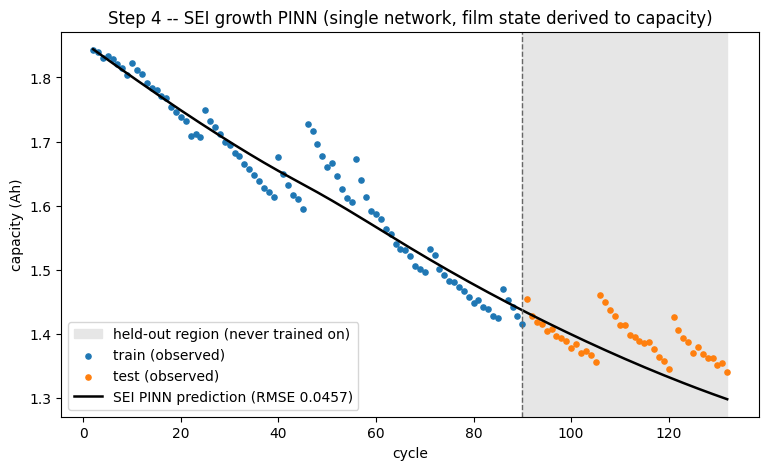

In [7]:
# Same plot layout as step1/step2: shade the held-out region, overlay the
# observed points, draw the model's prediction across the whole timeline.
with torch.no_grad():
    tau_all = torch.tensor(df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)
    q_pred_all = net.capacity(tau_all).squeeze().numpy()

plt.figure(figsize=(9, 5))
plt.axvspan(90, df.cycle.max(), color="0.9", label="held-out region (never trained on)")
plt.scatter(train_df.cycle, train_df.capacity_ah, s=14, color="tab:blue", label="train (observed)")
plt.scatter(test_df.cycle, test_df.capacity_ah, s=14, color="tab:orange", label="test (observed)")
plt.plot(df.cycle, q_pred_all, color="black", lw=1.8, label=f"SEI PINN prediction (RMSE {rmse:.4f})")
plt.axvline(90, color="0.4", ls="--", lw=1)
plt.xlabel("cycle"); plt.ylabel("capacity (Ah)")
plt.title("Step 4 -- SEI growth PINN (single network, film state derived to capacity)")
plt.legend()
plt.show()

## 7. Physical sanity checks

A plain curve-fitter has no invariants to check — it just outputs a number.
A physics model does, and this cell verifies them: capacity should equal
`Q0` exactly at cycle 1 (the hard initial condition), the film thickness
should stay positive, and capacity should stay finite. If the hard IC
construction in section 2 is correct, the first check passes to numerical
precision — that is the payoff for building the initial condition into the
functional form instead of hoping the optimiser finds it.

In [8]:
# Sanity checks that only make sense for a physics-constrained model --
# step1/step2's plain curve-fitters have no equivalent invariants to check.
with torch.no_grad():
    tau_check = torch.linspace(0, 1, 500).reshape(-1, 1)
    u_check = net.u(tau_check).squeeze().numpy()
    q_check = net.capacity(tau_check).squeeze().numpy()
    delta_check = np.sqrt(u_check)

failures = []
if abs(q_check[0] - Q0_AH) > 1e-4:
    failures.append(f"Q(0) != Q0: got {q_check[0]:.6f}, expected {Q0_AH}")  # hard IC should make this exact
if (delta_check <= 0).any():
    failures.append("film thickness went non-positive")
if not np.isfinite(q_check).all():
    failures.append("capacity contains NaN or inf")

print("FAILURES:", failures if failures else "none")

FAILURES: none
